# Chapter 4: RAG over internal docs

Companion notebook for [ch04/README.md](../README.md). Every number in the chapter comes from the
saved outputs below.

Prerequisites: `.env` configured, the ShopFlow database running (port 5433), and Ollama serving
`nomic-embed-text`. Hosted answer and judge
calls are cached in `eval/results/*.json`; delete a file to re-spend money and re-run it.

In [1]:
import json
import statistics
import sys
import time
from datetime import date
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd()))
from llmprod import get_settings

from ch04_rag import store
from ch04_rag.answer import generate
from ch04_rag.chunking import count_tokens
from ch04_rag.evalset import load_questions
from ch04_rag.judge import JUDGE_MODEL
from ch04_rag.retrieve import RERANK_MODEL, Retriever, fts_search, rrf, vector_search
from ch04_rag.runeval import (RESULTS, answer_eval, retrieval_eval, summarize_answers,
                              summarize_retrieval)

IMAGES = Path("../images")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
s = get_settings()


def openrouter_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key",
                  headers={"Authorization": f"Bearer {s.llm_api_key}"}, timeout=20)
    return r.json()["data"]["usage"]


usage_before = openrouter_usage()
print("run date:", date.today(), "| answer model:", s.llm_model, "| judge:", JUDGE_MODEL)
print("embeddings:", s.embed_model, "at", s.embed_base_url)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| torch", torch.__version__)
conn = store.open_db()
print(conn.execute("SELECT version()").fetchone()[0][:16], "| pgvector",
      conn.execute("SELECT extversion FROM pg_extension WHERE extname='vector'").fetchone()[0])

run date: 2026-11-09 | answer model: openai/gpt-6-luna | judge: openai/gpt-6-luna
embeddings: nomic-embed-text at http://localhost:11435/v1
GPU: NVIDIA GeForce RTX 3090 | torch 2.15.0+cu132
PostgreSQL 18.6  | pgvector 0.8.7


## The data: 36 Markdown documents

FAQ, policies, product care guides, the internal handbook and three incident runbooks.

In [2]:
docs = store.load_docs()
rows = [{"folder": p.split("/")[0] if "/" in p else "(root)", "doc": p,
         "tokens": count_tokens(t)} for p, t in docs.items()]
df_docs = pd.DataFrame(rows)
print(df_docs.groupby("folder").agg(docs=("doc", "count"), tokens=("tokens", "sum")))
print(f"\n{len(docs)} documents, {df_docs.tokens.sum():,} tokens (o200k_base); "
      f"largest: {df_docs.loc[df_docs.tokens.idxmax(), 'doc']} ({df_docs.tokens.max()} tokens)")

          docs  tokens
folder                
(root)       1     934
care         8    6725
handbook    11   10423
policies    13   10158
runbooks     3    2985

36 documents, 31,225 tokens (o200k_base); largest: handbook/holiday-peak-playbook.md (1051 tokens)


## Chunking: fixed windows vs headings

`fixed`: 512-token windows with 64 tokens of overlap. `heading`: one chunk per Markdown section
(split on paragraphs if a section exceeds 512 tokens), with the heading path kept as context.

chunker  chunks  min  mean  median  max
  fixed      79   70 430.1   512.0  512
heading     316   16  93.3    80.5  462


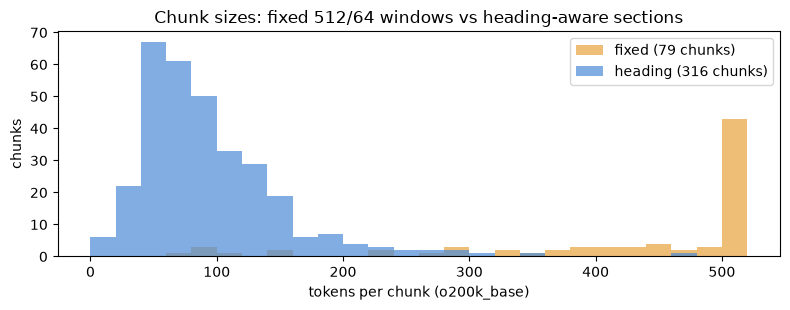

In [3]:
chunks = {ck: store.make_chunks(docs, ck) for ck in ("fixed", "heading")}
stats = pd.DataFrame([
    {"chunker": ck, "chunks": len(cs), "min": min(c.token_count for c in cs),
     "mean": round(statistics.mean(c.token_count for c in cs), 1),
     "median": statistics.median(c.token_count for c in cs),
     "max": max(c.token_count for c in cs)}
    for ck, cs in chunks.items()])
print(stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.2))
for ck, color in (("fixed", "#e8a33d"), ("heading", "#4c8bd6")):
    ax.hist([c.token_count for c in chunks[ck]], bins=range(0, 540, 20), alpha=0.7,
            label=f"{ck} ({len(chunks[ck])} chunks)", color=color)
ax.set_xlabel("tokens per chunk (o200k_base)")
ax.set_ylabel("chunks")
ax.set_title("Chunk sizes: fixed 512/64 windows vs heading-aware sections")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "04-chunk-sizes.png", dpi=150)
plt.show()

In [4]:
# The same fact, as each chunker sees it: the refund-timing section of the refund policy.
needle = "business days"
for ck in ("fixed", "heading"):
    c = next(c for c in chunks[ck] if c.doc_path == "policies/refund-policy.md" and needle in c.content)
    print(f"--- {c.citation} ({ck}, {c.token_count} tokens) heading_path={c.heading_path!r}")
    print(c.content[:420], "...\n")

--- [doc:policies/refund-policy.md#0] (fixed, 512 tokens) heading_path=''
# ShopFlow Refund Policy

*Owner: Customer Experience · Last reviewed: 2026-10-14*

This policy explains when and how ShopFlow issues refunds, how long they take, and what is included. All amounts are in US dollars (USD).

## Refund Timing

- **Returns:** Refunds are issued within **5-7 business days** after we receive and inspect your returned items. Your order status changes to *refunded* once the return is process ...

--- [doc:policies/refund-policy.md#1] (heading, 135 tokens) heading_path='ShopFlow Refund Policy > Refund Timing'
- **Returns:** Refunds are issued within **5-7 business days** after we receive and inspect your returned items. Your order status changes to *refunded* once the return is processed.
- **Cancelled orders:** If you cancel an order after payment, you receive a full refund within **5-7 business days** of the cancellation. The order status shows *cancelled*.
- **Failed payments:** If a p

## Ingest: embed with `nomic-embed-text`, store in pgvector + tsvector

`ingest()` replaces all rows of one chunker. We reset ch04's own table so the notebook is
reproducible.

In [5]:
store.setup(conn, reset=True)
ingest_stats = [store.ingest(conn, docs, ck) for ck in ("fixed", "heading")]
print(pd.DataFrame(ingest_stats).to_string(index=False))
print("rows:", store.counts(conn))
print(conn.execute(
    "SELECT indexname, indexdef FROM pg_indexes WHERE tablename = 'ch04_doc_chunks' ORDER BY 1"
).fetchall())

chunker  docs  chunks  tokens_min  tokens_mean  tokens_max  seconds
  fixed    36      79          70        430.1         512     17.4
heading    36     316          16         93.3         462     15.9
rows: {'fixed': 79, 'heading': 316}
[('ch04_chunks_fts', 'CREATE INDEX ch04_chunks_fts ON public.ch04_doc_chunks USING gin (tsv)'), ('ch04_chunks_hnsw', "CREATE INDEX ch04_chunks_hnsw ON public.ch04_doc_chunks USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')"), ('ch04_doc_chunks_chunker_doc_path_chunk_idx_key', 'CREATE UNIQUE INDEX ch04_doc_chunks_chunker_doc_path_chunk_idx_key ON public.ch04_doc_chunks USING btree (chunker, doc_path, chunk_idx)'), ('ch04_doc_chunks_pkey', 'CREATE UNIQUE INDEX ch04_doc_chunks_pkey ON public.ch04_doc_chunks USING btree (id)')]


### A filtered HNSW query can return fewer rows than `LIMIT`

Both chunkers live in one table, so every vector query filters on `chunker`. pgvector applies the
filter *after* the HNSW scan. At 395 rows the planner doesn't use the index at all (an exact sort
is cheaper), so we force it, as it would be at a few hundred thousand rows, and ask for 30
neighbours with iterative scans off, then on.

In [6]:
qv = store.embed_texts(["How long do refunds take?"], prefix=store.QUERY_PREFIX)[0]
SQL = ("EXPLAIN SELECT id FROM ch04_doc_chunks WHERE chunker = 'fixed'"
       " ORDER BY embedding <=> %s LIMIT 30")
print("planner's choice at 395 rows:", conn.execute(SQL, (qv,)).fetchall()[-1][0][:60])
conn.execute("SET enable_sort = off")  # pretend the table is big: force the HNSW index
print("forced:", " / ".join(r[0].strip()[:50] for r in conn.execute(SQL, (qv,)).fetchall()[:3]))
for setting in ("off", "strict_order"):
    conn.execute(f"SET hnsw.iterative_scan = {setting}")
    for ck in ("fixed", "heading"):
        n = len(vector_search(conn, qv, ck, 30))
        print(f"iterative_scan={setting:<12} chunker={ck:<8} asked 30, got {n}")
conn.execute("RESET enable_sort")
conn.execute("SET hnsw.iterative_scan = strict_order")  # what open_db() sets

planner's choice at 395 rows:                     Index Cond: (chunker = 'fixed'::text)
forced: Limit  (cost=184.82..1062.79 rows=10 width=16) / ->  Index Scan using ch04_chunks_hnsw on ch04_doc_ / Order By: (embedding <=> '[0.09185793,0.06606061,-
iterative_scan=off          chunker=fixed    asked 30, got 11
iterative_scan=off          chunker=heading  asked 30, got 29
iterative_scan=strict_order chunker=fixed    asked 30, got 30
iterative_scan=strict_order chunker=heading  asked 30, got 30


<psycopg.Cursor [COMMAND_OK] [IDLE] (host=localhost port=5433 database=shopflow) at 0x73ce0575a8d0>

## v0: vector search over fixed chunks

The version every tutorial builds: embed the question, take the 5 nearest chunks, paste them into
the prompt.

In [7]:
retriever = Retriever(conn, cache_queries=True)
SHOWCASE = [
    "What pattern do ShopFlow SKUs follow?",
    "Can I swap an item I bought for the same thing in a different size?",
    "What is ShopFlow's customer support phone number?",
]
v0_answers = []
for q in SHOWCASE:
    hits = retriever.retrieve(q, "vector", "fixed", 5)
    ans = generate(q, hits, prompt="v1")
    v0_answers.append(ans)
    print("Q:", q)
    for h in hits:
        print(f"   {h.rank}. {h.citation:<52} cos={h.score:.3f}")
    print("A:", ans.text)
    print(f"   {ans.latency_ms} ms, {ans.prompt_tokens}+{ans.completion_tokens} tokens, "
          f"${ans.cost_usd:.6f}\n")

Q: What pattern do ShopFlow SKUs follow?
   1. [doc:handbook/warehouse-operations.md#1]             cos=0.694
   2. [doc:handbook/holiday-peak-playbook.md#2]            cos=0.661
   3. [doc:policies/price-adjustment-policy.md#1]          cos=0.648
   4. [doc:runbooks/checkout-db-pool-exhaustion.md#1]      cos=0.644
   5. [doc:faq.md#0]                                       cos=0.642
A: I can't find that in the ShopFlow documents.
   1027 ms, 2175+14 tokens, $0.000279



Q: Can I swap an item I bought for the same thing in a different size?
   1. [doc:policies/order-cancellation.md#1]               cos=0.591
   2. [doc:policies/price-adjustment-policy.md#1]          cos=0.590
   3. [doc:policies/returns-policy.md#0]                   cos=0.578
   4. [doc:policies/damaged-or-defective-items.md#1]       cos=0.570
   5. [doc:care/wireless-earbuds.md#1]                     cos=0.555
A: I can't find that in the ShopFlow documents.
   1053 ms, 2007+14 tokens, $0.000258



Q: What is ShopFlow's customer support phone number?
   1. [doc:policies/account-security.md#0]                 cos=0.732
   2. [doc:faq.md#0]                                       cos=0.720
   3. [doc:policies/privacy-policy.md#0]                   cos=0.720
   4. [doc:policies/damaged-or-defective-items.md#0]       cos=0.711
   5. [doc:policies/payment-methods.md#1]                  cos=0.707
A: I can't find that in the ShopFlow documents.
   1705 ms, 2551+14 tokens, $0.000326



## Measuring retrieval: 35 answerable questions × 8 configurations

Two strictness levels. **Doc-level** recall@5: share of a question's evidence slots covered by
any chunk of a gold document in the top 5; MRR: mean of 1/rank of the first such chunk in the top
10. **Evidence-level**: the chunk must also contain the gold fact (the slot's `verify` regex). The 5 unanswerable questions have no gold and are
excluded here.

In [8]:
questions = load_questions()
print(len(questions), "questions:", pd.Series([q.category for q in questions]).value_counts().to_dict())
Retriever.cross_encoder()  # load once (GPU) so the first reranked question isn't billed for it
t0 = time.perf_counter()
ret = retrieval_eval(retriever, questions)
print(f"retrieval eval: {time.perf_counter() - t0:.1f} s")
(RESULTS / "retrieval.json").parent.mkdir(parents=True, exist_ok=True)
(RESULTS / "retrieval.json").write_text(json.dumps(ret, indent=1))
df_ret = pd.DataFrame(summarize_retrieval(ret))
print(df_ret.to_string(index=False))

40 questions: {'keyword': 11, 'paraphrase': 11, 'direct': 8, 'multi': 5, 'unanswerable': 5}


/home/a.saugi/llm-in-production/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 9496.13it/s]

retrieval eval: 4.2 s
         mode chunker  recall5   mrr  ev_recall5  ev_mrr  ev_r5_direct  ev_r5_keyword  ev_r5_multi  ev_r5_paraphrase
       vector   fixed     94.3 0.938        85.7   0.753         100.0           90.9         80.0              72.7
       vector heading    100.0 0.986        97.1   0.853         100.0           90.9        100.0             100.0
          fts   fixed     98.6 0.868        98.6   0.820         100.0          100.0         90.0             100.0
          fts heading     91.4 0.759        81.4   0.544          87.5           90.9         70.0              72.7
       hybrid   fixed     95.7 0.901        90.0   0.825         100.0           90.9         90.0              81.8
       hybrid heading     98.6 0.949        94.3   0.748         100.0          100.0         80.0              90.9
hybrid_rerank   fixed     97.1 0.925        97.1   0.891         100.0           90.9        100.0             100.0
hybrid_rerank heading     98.6 0.977      

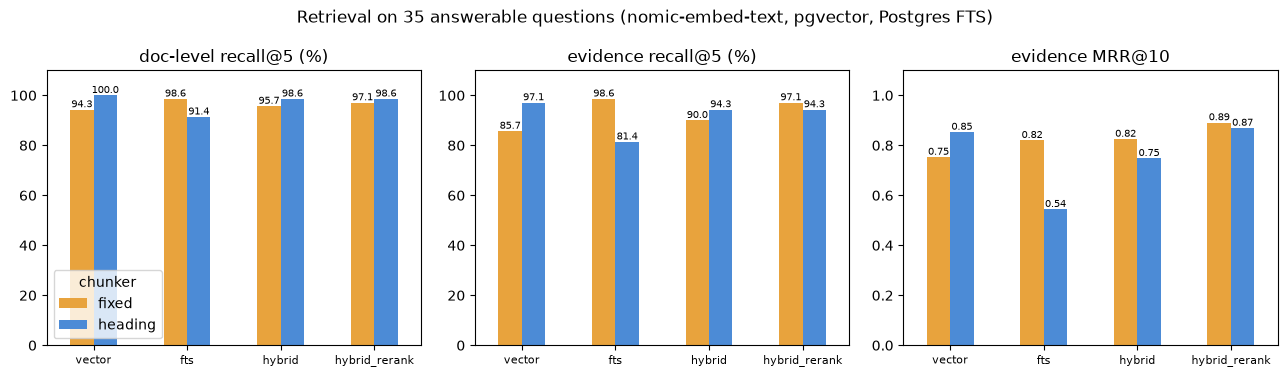

In [9]:
order = ["vector", "fts", "hybrid", "hybrid_rerank"]
panels = (("recall5", "doc-level recall@5 (%)"), ("ev_recall5", "evidence recall@5 (%)"),
          ("ev_mrr", "evidence MRR@10"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (metric, label) in zip(axes, panels):
    piv = df_ret.pivot(index="mode", columns="chunker", values=metric).loc[order]
    piv.plot.bar(ax=ax, color=["#e8a33d", "#4c8bd6"], rot=0, legend=metric == "recall5")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f" if metric == "ev_mrr" else "%.1f", fontsize=7)
    ax.set_ylim(0, 1.1 if metric == "ev_mrr" else 110)
fig.suptitle("Retrieval on 35 answerable questions (nomic-embed-text, pgvector, Postgres FTS)")
fig.tight_layout()
fig.savefig(IMAGES / "04-retrieval.png", dpi=150)
plt.show()

In [10]:
# Evidence misses per config: which questions lose the gold fact from the top 5?
for cfg, rows in ret.items():
    miss = [f"{r['id']}({r['ev_recall5']:.1f})" for r in rows if r["ev_recall5"] < 1]
    print(f"{cfg:<22} {len(miss):>2} misses: {' '.join(miss)}")
qtext = {q.id: q for q in questions}
for qid in ("q14", "q21", "q20"):
    print(f"\n{qid}: {qtext[qid].question}\n   gold: {qtext[qid].slots}")
    for cfg in ("vector|fixed", "hybrid_rerank|fixed", "hybrid_rerank|heading"):
        print(f"   {cfg:<22}", next(r["top5"][:3] for r in ret[cfg] if r["id"] == qid))

vector|fixed            6 misses: q03(0.0) q14(0.0) q15(0.0) q21(0.0) q33(0.5) q34(0.5)
vector|heading          1 misses: q03(0.0)
fts|fixed               1 misses: q34(0.5)
fts|heading             7 misses: q10(0.0) q12(0.0) q17(0.0) q20(0.0) q27(0.0) q34(0.0) q35(0.5)
hybrid|fixed            4 misses: q03(0.0) q14(0.0) q21(0.0) q34(0.5)
hybrid|heading          2 misses: q17(0.0) q34(0.0)
hybrid_rerank|fixed     1 misses: q03(0.0)
hybrid_rerank|heading   3 misses: q20(0.0) q31(0.5) q34(0.5)

q14: Can I swap an item I bought for the same thing in a different size?
   gold: (('policies/returns-policy.md',),)
   vector|fixed           ['[doc:policies/order-cancellation.md#1]', '[doc:policies/price-adjustment-policy.md#1]', '[doc:policies/returns-policy.md#0]']
   hybrid_rerank|fixed    ['[doc:policies/price-adjustment-policy.md#0]', '[doc:policies/returns-policy.md#1]', '[doc:policies/damaged-or-defective-items.md#0]']
   hybrid_rerank|heading  ['[doc:policies/returns-policy.md#6]', '[do

## Hybrid: what RRF does to one question

In [11]:
q = "What is the Loki query that finds 'db pool exhausted' errors?"
qv = retriever.embed_query(q)
vec = vector_search(conn, qv, "heading", 30)
fts = fts_search(conn, q, "heading", 30)
fused = rrf([[h.chunk_id for h in vec], [h.chunk_id for h in fts]])
pos_v = {h.chunk_id: h.rank for h in vec}
pos_f = {h.chunk_id: h.rank for h in fts}
cite = {h.chunk_id: h.citation for h in [*vec, *fts]}
print(f"{'fused':>5} {'vector':>6} {'fts':>4}  rrf      chunk")
for i, (cid, score) in enumerate(fused[:6], start=1):
    print(f"{i:>5} {pos_v.get(cid, '-'):>6} {pos_f.get(cid, '-'):>4}  {score:.4f}  {cite[cid]}")

fused vector  fts  rrf      chunk
    1      1    1  0.0328  [doc:runbooks/checkout-db-pool-exhaustion.md#2]
    2      4    3  0.0315  [doc:runbooks/checkout-db-pool-exhaustion.md#5]
    3      5    4  0.0310  [doc:runbooks/checkout-db-pool-exhaustion.md#3]
    4      8    2  0.0308  [doc:runbooks/payment-provider-timeout.md#3]
    5      3    8  0.0306  [doc:runbooks/checkout-db-pool-exhaustion.md#1]
    6      6    6  0.0303  [doc:runbooks/checkout-db-pool-exhaustion.md#4]


In [12]:
# Why we OR the question's words: websearch_to_tsquery ANDs them.
answerable = [qq for qq in questions if qq.answerable]
n_and = [conn.execute(
    "SELECT count(*) FROM ch04_doc_chunks WHERE chunker = 'fixed'"
    " AND tsv @@ websearch_to_tsquery('english', %s)", (qq.question,)).fetchone()[0]
    for qq in answerable]
n_or = [len(fts_search(conn, qq.question, "fixed", 100)) for qq in answerable]
for name, n in (("websearch_to_tsquery (AND)", n_and), ("OR of plainto_tsquery terms", n_or)):
    print(f"{name:<28} questions matching 0 chunks: {sum(x == 0 for x in n):>2}/{len(n)}, "
          f"median matches {statistics.median(n)}")

websearch_to_tsquery (AND)   questions matching 0 chunks: 26/35, median matches 0
OR of plainto_tsquery terms  questions matching 0 chunks:  0/35, median matches 57


## Reranking on the GPU

The cross-encoder reads (question, chunk) pairs together. On the Mac it hung on load; here
sentence-transformers runs on CUDA when the shared GPU has room, and falls back to the CPU when it
doesn't. We time 30 pairs on the shared model's device and on a dedicated CPU copy.

In [13]:
cands = retriever.retrieve(q, "hybrid", "heading", 30)
pairs = [(q, h.embed_text) for h in cands]


def time_predict(score, n=20):
    score(pairs)  # warm-up
    t = []
    for _ in range(n):
        t0 = time.perf_counter()
        score(pairs)
        t.append((time.perf_counter() - t0) * 1000)
    return statistics.median(t), sorted(t)[int(0.95 * len(t)) - 1]


from sentence_transformers import CrossEncoder

p50, p95 = time_predict(Retriever.rerank_scores)  # the shared model, with its CPU fallback
print(f"rerank 30 pairs, shared model on {Retriever.cross_encoder().model.device}: "
      f"p50 {p50:.1f} ms, p95 {p95:.1f} ms")
cpu = CrossEncoder(RERANK_MODEL, max_length=512, device="cpu")
p50, p95 = time_predict(lambda prs: cpu.predict(prs, show_progress_bar=False))
print(f"rerank 30 pairs, CPU (16 cores, shared host): p50 {p50:.1f} ms, p95 {p95:.1f} ms")
del cpu

rerank 30 pairs, shared model on cuda:0: p50 31.1 ms, p95 31.7 ms


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 20719.92it/s]

rerank 30 pairs, CPU (16 cores, shared host): p50 566.4 ms, p95 621.1 ms


In [14]:
# Per-stage latency of the final pipeline (hybrid_rerank, heading chunks, k=10), 40 questions.
lat = []
for qq in questions:
    retriever._qcache.pop(qq.question, None)  # measure the embedding call too
    t0 = time.perf_counter()
    retriever.retrieve(qq.question, "hybrid_rerank", "heading", 10)
    lat.append({**retriever.last_timing, "total_ms": (time.perf_counter() - t0) * 1000})
df_lat = pd.DataFrame(lat)
print(df_lat.describe(percentiles=[0.5, 0.95]).loc[["50%", "95%", "max"]].round(1).to_string())

     embed_ms  vector_ms  fts_ms  rerank_ms  total_ms
50%      16.1        2.0     1.5       36.8      56.6
95%      21.6        2.2     4.3       49.0      70.2
max      26.5        2.5     6.9       49.7      75.4


## Answers v1: `gpt-6-luna` answers, chapter 3's judge (`gpt-6-luna`)

All 40 questions under all 8 retrieval configs with the top 5 chunks and prompt v1 ("at most 4
sentences"), plus a no-retrieval baseline that puts the whole corpus (about 31k tokens) into every
prompt. Cached in `eval/results/answers_luna_v1.json`.

In [15]:
t0 = time.perf_counter()
ans_v1 = answer_eval(retriever, questions, RESULTS / "answers_luna_v1.json", prompt="v1")
print(f"{time.perf_counter() - t0:.1f} s (under 1 s means: loaded from cache)")
df_v1 = pd.DataFrame(summarize_answers(ans_v1, questions))
print(df_v1.to_string(index=False))


def spent(res):
    return sum(r["cost_usd"] for rows in res["configs"].values() for r in rows)


print(f"\ncost of this eval (generation + judge, OpenRouter usage.cost): ${spent(ans_v1):.4f}")

0.0 s (under 1 s means: loaded from cache)
               config  correct_answerable  refused_unanswerable  false_refusal  faithful  bad_citations  uncited  latency_p50_ms  prompt_tokens  usd_per_1k
         vector|fixed                71.4                 100.0            5.7      95.0              0        0            1520           2285       0.308
       vector|heading                74.3                 100.0            2.9      97.5              0        0            1442            841       0.111
            fts|fixed                68.6                 100.0            0.0      97.5              0        0            1302           2708       0.363
          fts|heading                54.3                 100.0           17.1      92.5              0        0            1345           1109       0.152
         hybrid|fixed                68.6                 100.0            5.7      97.5              0        0            1474           2581       0.346
       hybrid|heading

In [16]:
# The 9 hybrid_rerank|heading failures: what did the judge object to?
qd = {q.id: q for q in questions}
for r in ans_v1["configs"]["hybrid_rerank|heading"]:
    if not r["correct"] or r["faithful"] is False:
        print(f"{r['id']} [{r['category']}] faithful={r['faithful']}  judge: {r['reason'][:150]}")

q19 [paraphrase] faithful=True  judge: The answer correctly says not to machine wash and gives the supported reason, but omits the recommended mild-soap-and-water wipe and air-drying method
q20 [paraphrase] faithful=True  judge: The answer omits the key fact that electronics have a 1-year limited warranty from the delivery date, but its statements are supported by the provided
q21 [paraphrase] faithful=True  judge: The answer omits that a paid cancellation is refunded in full and that support should be asked to lock the account if unauthorized access is suspected
q24 [direct] faithful=True  judge: The answer gives the correct price but omits that express shipping is available only for US addresses; its stated price is supported by the context.
q29 [direct] faithful=True  judge: The answer omits the reference’s request to include photos of the product label and affected area if possible, though its other advice is supported by
q31 [multi] faithful=True  judge: The answer omits the requi

In [17]:
# Is the missing fact in the context at all? Rank of the first chunk containing it (top 10).
import re

MISSING = {"q19": r"(?i)mild soap", "q21": r"(?i)lock", "q24": r"US addresses only",
           "q29": r"(?i)photo",
           "q31": r"deployctl rollback", "q32": r"(?i)kill long|raise the pool",
           "q34": r"(?i)quarantine", "q35": r"(?i)receive and inspect", "q20": r"\*\*1 year\*\*"}
for qid, pat in MISSING.items():
    hits = retriever.retrieve(qd[qid].question, "hybrid_rerank", "heading", 10)
    ranks = [h.rank for h in hits if re.search(pat, h.embed_text)]
    print(f"{qid} /{pat}/ found at ranks {ranks or 'none in top 10'}")

q19 /(?i)mild soap/ found at ranks [2, 5, 10]
q21 /(?i)lock/ found at ranks [4, 9]
q24 /US addresses only/ found at ranks [3]
q29 /(?i)photo/ found at ranks [2, 7]


q31 /deployctl rollback/ found at ranks [6, 9, 10]


q32 /(?i)kill long|raise the pool/ found at ranks none in top 10
q34 /(?i)quarantine/ found at ranks [9]
q35 /(?i)receive and inspect/ found at ranks [3, 10]
q20 /\*\*1 year\*\*/ found at ranks [7]


## Iteration: prompt v2 (complete, not short)

Same grounding rules; rule 4 now asks for every condition, exception and limit instead of a
sentence budget. All 8 RAG configs again, top 5. Cached in `eval/results/answers_luna_v2.json`.

In [18]:
ans_v2 = answer_eval(retriever, questions, RESULTS / "answers_luna_v2.json", prompt="v2",
                     whole_corpus=False)
df_v2 = pd.DataFrame(summarize_answers(ans_v2, questions))
cmp = df_v1[df_v1.config != "whole_corpus"][["config", "correct_answerable", "faithful"]].merge(
    df_v2[["config", "correct_answerable", "faithful", "prompt_tokens"]], on="config",
    suffixes=("_v1", "_v2"))
print(cmp.to_string(index=False))
print(f"\ncost: ${spent(ans_v2):.4f}")

               config  correct_answerable_v1  faithful_v1  correct_answerable_v2  faithful_v2  prompt_tokens
         vector|fixed                   71.4         95.0                   74.3        100.0           2358
       vector|heading                   74.3         97.5                   71.4         97.5            914
            fts|fixed                   68.6         97.5                   77.1        100.0           2781
          fts|heading                   54.3         92.5                   62.9         97.5           1182
         hybrid|fixed                   68.6         97.5                   80.0         97.5           2654
       hybrid|heading                   68.6         97.5                   77.1        100.0           1014
  hybrid_rerank|fixed                   74.3         97.5                   80.0         97.5           2660
hybrid_rerank|heading                   74.3         97.5                   71.4        100.0            950

cost: $0.1554


## Iteration: read more small chunks (k = 10)

Heading chunks average 93 tokens, so five of them are about 500 tokens of context; five fixed
chunks are about 2,150. We give the reranked heading pipeline 10 chunks (and fixed too, for
comparison). Cached in `eval/results/answers_luna_v2_k10.json`.

In [19]:
ans_k10 = answer_eval(retriever, questions, RESULTS / "answers_luna_v2_k10.json", prompt="v2",
                      whole_corpus=False, k=10,
                      configs=[("hybrid_rerank", "heading"), ("hybrid_rerank", "fixed")])
df_k10 = pd.DataFrame(summarize_answers(ans_k10, questions))
print(df_k10.to_string(index=False))
print(f"\ncost: ${spent(ans_k10):.4f}")
for r in ans_k10["configs"]["hybrid_rerank|heading"]:
    if not r["correct"] or r["faithful"] is False:
        print(f"\n{r['id']}: {r['answer'][:400]}\n   judge: {r['reason']}")

               config  correct_answerable  refused_unanswerable  false_refusal  faithful  bad_citations  uncited  latency_p50_ms  prompt_tokens  usd_per_1k
hybrid_rerank|heading                85.7                 100.0            0.0     100.0              0        0            1269           1679       0.241
  hybrid_rerank|fixed                77.1                 100.0            2.9      92.5              0        0            1284           4995       0.656

cost: $0.0745

q19: No. The guide says not to machine wash a yoga mat because heat and agitation can break down the foam and surface. [doc:care/yoga-mats.md#4]
   judge: The answer correctly says not to machine wash it and gives the supported reason, but omits the reference’s recommended alternative of wiping with mild soap and water and air drying.

q24: Express shipping costs $14.99. [doc:faq.md#2]
   judge: The price is correct, but the answer omits the reference’s key qualifier that express shipping is available only for 

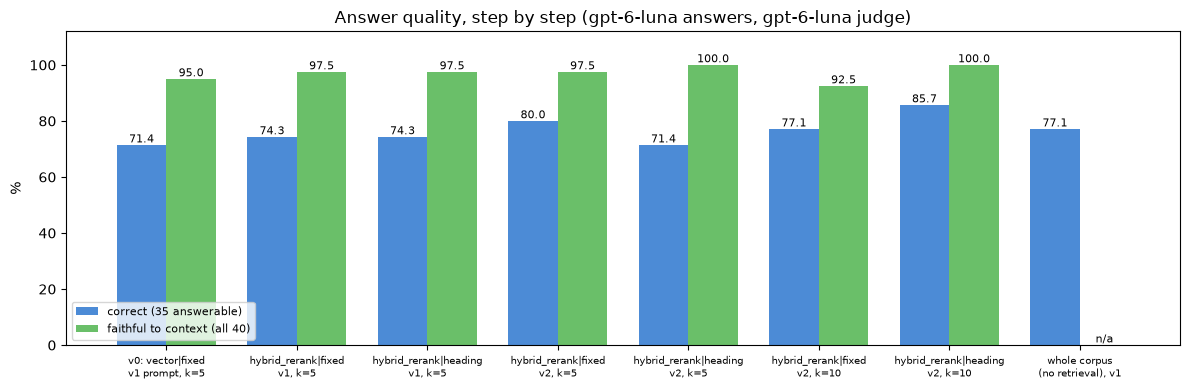

In [20]:
steps = [
    ("v0: vector|fixed\nv1 prompt, k=5", df_v1, "vector|fixed"),
    ("hybrid_rerank|fixed\nv1, k=5", df_v1, "hybrid_rerank|fixed"),
    ("hybrid_rerank|heading\nv1, k=5", df_v1, "hybrid_rerank|heading"),
    ("hybrid_rerank|fixed\nv2, k=5", df_v2, "hybrid_rerank|fixed"),
    ("hybrid_rerank|heading\nv2, k=5", df_v2, "hybrid_rerank|heading"),
    ("hybrid_rerank|fixed\nv2, k=10", df_k10, "hybrid_rerank|fixed"),
    ("hybrid_rerank|heading\nv2, k=10", df_k10, "hybrid_rerank|heading"),
    ("whole corpus\n(no retrieval), v1", df_v1, "whole_corpus"),
]
vals = [d.set_index("config").loc[c] for _, d, c in steps]
fig, ax = plt.subplots(figsize=(12, 4))
x = range(len(steps))
w = 0.38
b1 = ax.bar([i - w / 2 for i in x], [v.correct_answerable for v in vals], w,
            label="correct (35 answerable)", color="#4c8bd6")
faith = [v.faithful for v in vals]
b2 = ax.bar([i + w / 2 for i in x], [f if f == f else 0 for f in faith], w,
            label="faithful to context (all 40)", color="#6abf69")
ax.bar_label(b1, fmt="%.1f", fontsize=8)
ax.bar_label(b2, labels=[f"{f:.1f}" if f == f else "n/a" for f in faith], fontsize=8)
ax.set_xticks(list(x), [s[0] for s in steps], fontsize=7.5)
ax.set_ylim(0, 112)
ax.set_ylabel("%")
ax.set_title("Answer quality, step by step (gpt-6-luna answers, gpt-6-luna judge)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "04-answers.png", dpi=150)
plt.show()

In [21]:
# Citations: are they there, and do they point at chunks we actually retrieved?
for name, res in (("v1 k=5", ans_v1), ("v2 k=5", ans_v2), ("v2 k=10", ans_k10)):
    for cfg, rows in res["configs"].items():
        if cfg == "whole_corpus":
            continue
        n = sum(len(r["cites"]) for r in rows)
        bad = sum(len(r["invalid_cites"]) for r in rows)
        print(f"{name:<8} {cfg:<22} citations={n:>3}  not-in-retrieved={bad}")

v1 k=5   vector|fixed           citations= 45  not-in-retrieved=0
v1 k=5   vector|heading         citations= 50  not-in-retrieved=0
v1 k=5   fts|fixed              citations= 53  not-in-retrieved=0
v1 k=5   fts|heading            citations= 42  not-in-retrieved=0
v1 k=5   hybrid|fixed           citations= 44  not-in-retrieved=0
v1 k=5   hybrid|heading         citations= 49  not-in-retrieved=0
v1 k=5   hybrid_rerank|fixed    citations= 46  not-in-retrieved=0
v1 k=5   hybrid_rerank|heading  citations= 45  not-in-retrieved=0
v2 k=5   vector|fixed           citations= 54  not-in-retrieved=0
v2 k=5   vector|heading         citations= 57  not-in-retrieved=0
v2 k=5   fts|fixed              citations= 54  not-in-retrieved=0
v2 k=5   fts|heading            citations= 50  not-in-retrieved=0
v2 k=5   hybrid|fixed           citations= 52  not-in-retrieved=0
v2 k=5   hybrid|heading         citations= 60  not-in-retrieved=0
v2 k=5   hybrid_rerank|fixed    citations= 57  not-in-retrieved=0
v2 k=5   h

## Optional: a local generator (`qwen3:8b` on Ollama)

Same final retrieval (hybrid + rerank, heading chunks, k = 10), prompt v2, same judge; only
generation moves to Ollama. Off by default; set `CH04_RUN_LOCAL=1` to run it (about 40 local
calls). Cached in `eval/results/answers_qwen3-8b.json`.

In [22]:
import os

if os.environ.get("CH04_RUN_LOCAL") == "1" or (RESULTS / "answers_qwen3-8b.json").exists():
    ans_qwen = answer_eval(retriever, questions, RESULTS / "answers_qwen3-8b.json",
                           model="qwen3:8b", configs=[("hybrid_rerank", "heading")],
                           whole_corpus=False, k=10, prompt="v2", workers=2)
    qwen = pd.DataFrame(summarize_answers(ans_qwen, questions))
    qwen.insert(0, "model", "qwen3:8b (Ollama)")
    luna = df_k10[df_k10.config == "hybrid_rerank|heading"].copy()
    luna.insert(0, "model", "openai/gpt-6-luna")
    print(pd.concat([luna, qwen]).to_string(index=False))
    print(f"judge cost: ${spent(ans_qwen):.4f}")
else:
    print("skipped: set CH04_RUN_LOCAL=1 to generate with qwen3:8b on Ollama")

            model                config  correct_answerable  refused_unanswerable  false_refusal  faithful  bad_citations  uncited  latency_p50_ms  prompt_tokens  usd_per_1k
openai/gpt-6-luna hybrid_rerank|heading                85.7                 100.0            0.0     100.0              0        0            1269           1679       0.241
qwen3:8b (Ollama) hybrid_rerank|heading                82.9                 100.0            0.0      95.0              0        0            1091           1730       0.000
judge cost: $0.0112


## Serving it: the FastAPI endpoint, in process

In [23]:
from fastapi.testclient import TestClient

from app import app

QUESTION = "A bad deploy broke checkout during the Black Friday freeze. Can we ship a fix?"
with TestClient(app) as client:  # `with` runs the lifespan: the reranker loads first
    resp = client.post("/ask", json={"question": QUESTION})
print(resp.status_code)
body = resp.json()
print(body["answer"], "\n")
for src in body["sources"]:
    print(f"  {src['citation']:<52} {src['score']:>7.3f}  {src['heading_path'][:60]}")
print({k: body[k] for k in ("refused", "invalid_citations", "timing_ms", "prompt_tokens",
                            "completion_tokens", "cost_usd")})

200
Only a SEV1 or SEV2 fix may ship during the freeze, and it requires sign-off from the engineering on-call lead. [doc:handbook/holiday-peak-playbook.md#2] The documents do not specify whether a particular checkout failure qualifies as SEV1 or SEV2; checkout down or payments failing >20% is SEV1, while error rate >5% or p95 latency >2s for 10 minutes is SEV2. [doc:runbooks/checkout-bad-deploy.md#2] 

  [doc:runbooks/checkout-bad-deploy.md#8]               -0.216  Runbook: Checkout Bad Deploy > 5. Investigate afterward
  [doc:handbook/holiday-peak-playbook.md#2]             -0.606  Holiday Peak Playbook (Black Friday – Cyber Monday) > Key Da
  [doc:runbooks/checkout-bad-deploy.md#7]               -0.715  Runbook: Checkout Bad Deploy > 4. Check for customer impact
  [doc:runbooks/checkout-bad-deploy.md#1]               -0.761  Runbook: Checkout Bad Deploy > Purpose
  [doc:runbooks/checkout-bad-deploy.md#9]               -1.886  Runbook: Checkout Bad Deploy > Escalation
  [doc:runbooks/

In [24]:
usage_after = openrouter_usage()
print(f"OpenRouter key usage during this notebook run: ${usage_after - usage_before:.4f} "
      "(includes any other process sharing the key)")
conn.close()

OpenRouter key usage during this notebook run: $0.0102 (includes any other process sharing the key)
